# Fraud Detection: Error Analysis (tuned LightGBM)

Milestone 3. The tuned LightGBM from [09_hyperparameter-tuning.ipynb](09_hyperparameter-tuning.ipynb) is our best model (validation ROC-AUC 0.774). A score tells us **how good** the model is. An error analysis tells us **where it is wrong and why**.

**How:**
1. We use a realistic cut-off: STEG inspects the **10% of clients with the highest fraud score**. (STEG's real inspection capacity is not known yet; 10% is our working scenario.)
2. This splits the clients into four groups:

| Group | Meaning |
|---|---|
| **Caught fraud** (true positive) | fraud, and in the top 10% |
| **Missed fraud** (false negative) | fraud, but not in the top 10% |
| **False alarm** (false positive) | honest, but in the top 10% |
| **Correct no-fraud** (true negative) | honest, and not in the top 10% |

3. We compare the groups, check how well the model works for different kinds of clients (segments), and look at the hardest cases.

**How this helps:** every weakness points to something the model is missing: a new feature to try, a limit of the data to mention honestly, or advice for STEG on where the model can and cannot be trusted.

We use only the **validation split**: the model never trained on these clients, so its errors here are realistic. The notebook shows tables and one chart, the confusion matrix.

In [1]:
# libraries for data handling, loading the saved model and the metrics
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, roc_auc_score

pd.set_option("display.max_columns", 40)
FEATURE_DIR = Path("data/features")
CLEAN_DIR = Path("data/clean")
TOP_SHARE = 0.10    # STEG inspects the top 10% of clients

## 1. Load the data and the tuned model

- Validation features and labels from [06_feature-engineering.ipynb](06_feature-engineering.ipynb).
- The tuned model saved in notebook 09 (`models/lightgbm_tuned.txt`).
- The client creation date from the cleaned client table, only to check client age (it is not a model feature).

In [2]:
# read one feature table from data/features, with client_id as the index
def load(name):
    return pd.read_csv(FEATURE_DIR / f"{name}.csv", index_col="client_id")

X_valid = load("X_valid")
y_valid = load("y_valid")["target"]

# the tuned LightGBM from notebook 09; predict() returns the fraud probability
model = lgb.Booster(model_file="models/lightgbm_tuned.txt")

# creation year of each validation client (for the client-age check only)
clients = pd.read_csv(CLEAN_DIR / "client_train_clean.csv", parse_dates=["creation_date"], index_col="client_id")
creation_year = clients.loc[X_valid.index, "creation_date"].dt.year

print("validation clients:", len(X_valid), "| fraud:", int(y_valid.sum()))

validation clients: 27099 | fraud: 1513


## 2. Scores, cut-off and the four groups

In [3]:
# one table with the features, the true label, the fraud score and the creation year
data = X_valid.copy()
data["target"] = y_valid
data["score"] = model.predict(X_valid)
data["creation_year"] = creation_year

# the model's ROC-AUC on validation, as a check that the saved model is the tuned one
print(f"ROC-AUC: {roc_auc_score(data['target'], data['score']):.4f}")

# cut-off: the score above which the top 10% of clients lie
cut_off = data["score"].quantile(1 - TOP_SHARE)
data["flagged"] = (data["score"] >= cut_off).astype(int)
print(f"cut-off score for the top {TOP_SHARE:.0%}: {cut_off:.3f}")

# name the four groups
group_names = {(1, 1): "caught fraud", (1, 0): "missed fraud", (0, 1): "false alarm", (0, 0): "correct no-fraud"}
data["group"] = [group_names[(t, f)] for t, f in zip(data["target"], data["flagged"])]

groups = data["group"].value_counts().reindex(group_names.values())
print()
print(groups.to_string())

tp, fn, fp = groups["caught fraud"], groups["missed fraud"], groups["false alarm"]
print()
print(f"fraud caught (recall): {tp / (tp + fn):.1%}   hit rate of the visits (precision): {tp / (tp + fp):.1%}")

ROC-AUC: 0.7742
cut-off score for the top 10%: 0.690

group
caught fraud          517
missed fraud          996
false alarm          2193
correct no-fraud    23393

fraud caught (recall): 34.2%   hit rate of the visits (precision): 19.1%


### Confusion matrix (top 10% flagged)

The same four groups as a confusion matrix: rows = the real class, columns = what the model says at the top-10% cut-off.

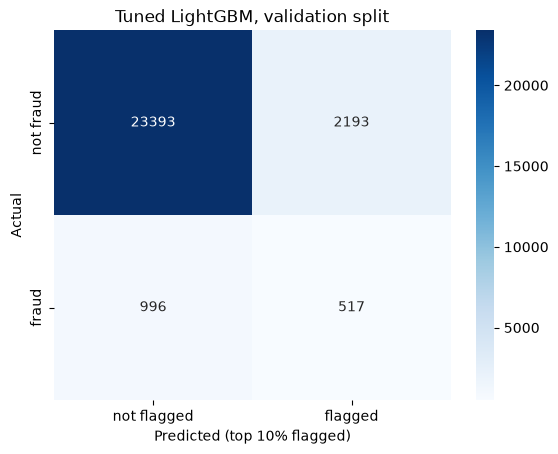

In [4]:
# confusion matrix: rows = actual class, columns = flagged or not
cm = confusion_matrix(data["target"], data["flagged"])

sns.heatmap(cm, annot=True, fmt="g", cmap="Blues",
            xticklabels=["not flagged", "flagged"], yticklabels=["not fraud", "fraud"])
plt.xlabel("Predicted (top 10% flagged)")
plt.ylabel("Actual")
plt.title("Tuned LightGBM, validation split")
plt.show()

## 3. What do the groups look like?

The key features per group: medians for numbers, shares (in %) for yes/no properties. The most important comparison is **missed fraud vs caught fraud**: what is different about the fraud cases the model does not find?

In [5]:
# yes/no properties used in the tables below
data["electricity only"] = data["cons_std_gaz"].isna()        # no gas bill at all
data["has gas"] = data["cons_std_gaz"].notna()
data["category 51"] = data["client_catg"] == 51

median_columns = ["n_bills", "cons_mean", "cons_max", "consommation_level_1_sum",
                  "consommation_level_3_max", "max_change", "backward_count", "creation_year", "score"]
share_columns = ["category 51", "has_backward", "electricity only", "has gas"]

order = list(group_names.values())
by_group = data.groupby("group")
profile = pd.concat([
    by_group[median_columns].median().T,
    (by_group[share_columns].mean().T * 100).rename(index=lambda c: f"{c} (%)"),
]).reindex(columns=order)
profile.loc["clients"] = groups[order]
profile.round(2)

group,caught fraud,missed fraud,false alarm,correct no-fraud
n_bills,51.00,39.00,45.00,26.00
cons_mean,618.61,400.90,597.25,379.27
cons_max,3367.00,1665.00,3090.00,1181.00
consommation_level_1_sum,19437.00,14282.00,18201.00,8444.00
consommation_level_3_max,800.00,0.00,786.00,0.00
max_change,2723.00,1234.50,2552.00,813.00
backward_count,0.00,0.00,0.00,0.00
creation_year,2002.00,2002.00,2004.00,2006.00
score,0.78,0.52,0.75,0.31
category 51 (%),8.51,1.91,5.20,0.86


## 4. How well does the model work for whom? (segments)

For each kind of client:
- **ROC-AUC inside the segment**: how well the model ranks fraud above honest clients within this group (0.5 = coin flip),
- **fraud caught**: the share of the segment's fraud cases that land in the overall top 10%,
- **flagged**: the share of the segment's clients in the top 10%.

A segment with a low ROC-AUC or few caught fraud cases is a weak spot.

In [6]:
def segment_table(segment):
    rows = {}
    for name, part in data.groupby(segment, observed=True):
        fraud = part["target"] == 1
        rows[name] = {
            "clients": len(part),
            "fraud rate (%)": fraud.mean() * 100,
            # ROC-AUC needs both fraud and honest clients in the segment
            "ROC-AUC": roc_auc_score(part["target"], part["score"]) if part["target"].nunique() == 2 else np.nan,
            "fraud caught (%)": part.loc[fraud, "flagged"].mean() * 100 if fraud.any() else np.nan,
            "flagged (%)": part["flagged"].mean() * 100,
        }
    return pd.DataFrame(rows).T.round(3)

### Bill history (number of bills, the same groups as in the EDA)

In [7]:
# number of bills in three groups, as in the EDA
data["bill history"] = pd.cut(data["n_bills"], [0, 10, 50, np.inf], labels=["1-10 bills", "11-50 bills", "51+ bills"])
segment_table("bill history")

,clients,fraud rate (%),ROC-AUC,fraud caught (%),flagged (%)
1-10 bills,6948.0,1.223,0.800,4.706,0.518
11-50 bills,13590.0,5.901,0.723,30.923,10.397
51+ bills,6561.0,9.541,0.716,42.332,19.220


### Meters (electricity, gas or both)

In [8]:
# which meters a client has bills on (NaN in the per-meter std = no bill on that meter)
data["meters"] = np.select(
    [data["cons_std_gaz"].isna(), data["cons_std_elec"].isna()],
    ["electricity only", "gas only"],
    default="electricity and gas",
)
segment_table("meters")

,clients,fraud rate (%),ROC-AUC,fraud caught (%),flagged (%)
electricity and gas,12103.0,7.527,0.740,36.114,13.418
electricity only,14872.0,4.041,0.789,31.281,7.302
gas only,124.0,0.806,0.943,0.000,0.000


### Client category

In [9]:
segment_table("client_catg")

,clients,fraud rate (%),ROC-AUC,fraud caught (%),flagged (%)
11,26278.0,5.453,0.770,32.519,9.529
12,442.0,3.846,0.818,41.176,10.860
51,379.0,16.623,0.770,69.841,41.689


### Region (the 6 largest regions, all others grouped)

In [10]:
# keep the 6 regions with the most validation clients, group the rest as "other"
largest = data["region"].value_counts().head(6).index
data["region group"] = data["region"].where(data["region"].isin(largest), "other").astype(str)
segment_table("region group")

,clients,fraud rate (%),ROC-AUC,fraud caught (%),flagged (%)
101,6832.0,3.454,0.739,8.051,1.434
103,1820.0,10.385,0.767,60.317,28.736
104,2546.0,5.931,0.742,30.464,11.469
107,2008.0,6.673,0.751,36.567,12.251
301,1898.0,3.477,0.776,22.727,3.003
311,2440.0,8.115,0.751,42.929,18.402
other,9555.0,5.641,0.773,35.065,10.937


### Client age (creation year)

Client age is **not** a model feature (the team decided against time features in v1). If the model is clearly weaker for young or old clients, that is a reason to revisit this decision.

In [11]:
# creation year in three groups
data["client age"] = pd.cut(data["creation_year"], [0, 1999, 2009, 3000],
                            labels=["created before 2000", "created 2000-2009", "created 2010 or later"])
segment_table("client age")

,clients,fraud rate (%),ROC-AUC,fraud caught (%),flagged (%)
created before 2000,9729.0,6.897,0.791,34.277,10.330
created 2000-2009,7896.0,6.066,0.743,37.787,13.614
created 2010 or later,9474.0,3.832,0.761,29.201,6.650


## 5. The hardest missed fraud cases

The 10 fraud clients with the **lowest** scores: the model is most sure they are honest. Their features show what kind of fraud is invisible to the model.

In [12]:
show = ["score", "n_bills", "cons_mean", "cons_max", "consommation_level_1_sum", "consommation_level_3_max",
        "max_change", "backward_count", "client_catg", "region", "meters", "creation_year"]
data[data["target"] == 1].nsmallest(10, "score")[show].round(3)

,score,n_bills,cons_mean,cons_max,consommation_level_1_sum,consommation_level_3_max,max_change,backward_count,client_catg,region,meters,creation_year
client_id,,,,,,,,,,,,
train_Client_49340,0.026,3,215.667,418,647,0,396.0,0,11,101,electricity only,2015
train_Client_7198,0.030,17,441.176,627,7500,0,325.0,0,11,313,electricity only,2013
train_Client_56221,0.042,4,0.000,0,0,0,0.0,0,11,301,electricity and gas,2013
train_Client_44401,0.042,2,1256.000,1259,2000,59,6.0,0,11,104,electricity only,2016
train_Client_126280,0.053,10,139.300,778,1393,0,112.0,0,11,312,electricity and gas,2012
train_Client_57076,0.053,3,454.000,775,1362,0,637.0,0,11,101,electricity only,2018
train_Client_79017,0.054,7,32.286,53,226,0,29.0,0,11,103,electricity only,2016
train_Client_11551,0.056,4,311.750,564,1247,0,261.0,0,11,104,electricity only,2014
train_Client_57180,0.058,34,3884.235,7590,42400,2400,5580.0,0,11,101,electricity only,2002


## 6. The strongest false alarms

The 10 honest clients with the **highest** scores. They are either unusual honest clients, or fraud that STEG has not detected yet (the labels only show detected fraud).

In [13]:
data[data["target"] == 0].nlargest(10, "score")[show].round(3)

,score,n_bills,cons_mean,cons_max,consommation_level_1_sum,consommation_level_3_max,max_change,backward_count,client_catg,region,meters,creation_year
client_id,,,,,,,,,,,,
train_Client_42343,0.920,44,2362.295,19545,20665,2400,19545.0,0,51,304,electricity only,1986
train_Client_89995,0.920,187,1042.144,16095,59563,1400,15167.0,0,11,103,electricity and gas,2002
train_Client_7252,0.915,34,3019.382,13367,20839,800,10262.0,0,51,104,electricity only,2007
train_Client_47463,0.915,52,805.173,10503,13867,2400,9298.0,0,51,103,electricity and gas,2012
train_Client_47876,0.910,32,2134.844,13374,17859,1000,10330.0,0,51,104,electricity and gas,2017
train_Client_109768,0.909,48,2110.646,15910,18741,800,11332.0,0,51,103,electricity and gas,2013
train_Client_22095,0.908,60,1217.533,3736,41358,400,3126.0,0,51,107,electricity and gas,2012
train_Client_30534,0.907,168,3156.774,16528,88722,600,13618.0,6,51,106,electricity and gas,1985
train_Client_76334,0.900,171,1259.708,14777,35743,1600,11366.0,0,11,104,electricity and gas,1997


## Findings and improvements

With the top-10% scenario, STEG would visit 2,710 clients and catch **517 of 1,513 fraud cases (34%)**, with a hit rate of **19%** (random visits: 5.6%). Below are the main findings. Each one comes with an idea for improving the model.

**1. The model mainly finds fraud with high consumption and misses fraud that looks "normal".**
Caught fraud has a median of 619 per bill, a level-3 maximum of 800 and big jumps (2,723). Missed fraud looks much more like honest clients: 401 per bill, no level-3 consumption (median 0) and smaller jumps (1,235). The false alarms look almost exactly like caught fraud. So the model has learned "big, unusual consumers are risky". Fraud that *hides* consumption (low bills) is mostly missed.
→ *Improvement:* features that compare a client **with their own past**, e.g. the drop in consumption between the first and the last years, or the share of bills with zero consumption. Also features that compare a client **with similar clients** (consumption vs. the median of the same region and tariff).

**2. The sum features make long histories look risky.**
Clients with 1–10 bills: the model ranks them well within their group (ROC-AUC 0.80), but only 0.5% of them are flagged and only 5% of their fraud is caught. Clients with 51+ bills: 19% are flagged. Columns like `consommation_level_1_sum` grow with the number of bills, so a long history alone pushes the score up.
→ *Improvement:* try **per-bill or per-month versions** of the sum features (sum divided by `n_bills` or by months billed) next to the sums. The team dropped the mean per level in feature engineering because "mean = sum / n_bills adds nothing". This finding suggests that it may help tree models after all, so it is worth one validation test.

**3. The model is weakest for long-history clients and clients with both meters.**
ROC-AUC inside the segment: 0.716 for 51+ bills, 0.723 for 11–50 bills, 0.740 for electricity and gas. These clients have up to 15 years of bills, and our features summarise the whole history in one number, so recent changes are diluted.
→ *Improvement:* **time-window features**, e.g. consumption in the last 2 years vs. the years before. These are time features, which the team parked for v1. The error analysis gives a reason to revisit that decision.

**4. Client age matters a little.**
Clients created in 2010 or later: only 29% of their fraud is caught (vs. 34–38% for older clients). Clients created before 2000 are ranked best (ROC-AUC 0.791). This is a small effect, but it supports point 3.
→ *Improvement:* test **client age** (from `creation_date`) as a feature, together with the time-window features.

**5. Some regions are almost never flagged.**
Region 101, the largest region (6,832 validation clients), has a fraud rate of 3.5%, but only 1.4% of its clients are flagged and only 8% of its fraud is caught. In region 103, 60% is caught. The model's flags are concentrated in a few regions.
→ *Improvement:* region-relative features (see point 1). *For STEG:* the top-10% list should not be the only basis for inspections in region 101.

**6. Part of the fraud is invisible in the bills (data limit).**
The 10 fraud clients with the lowest scores are mostly young, category-11, electricity-only clients with few bills and low, stable consumption. Nothing in their bills stands out. No feature built from bills alone will find them, so this is an honest limit to mention in the presentation.

**7. Many "false alarms" may be undetected fraud.**
The honest clients with the highest scores are big consumers with very large jumps (up to 19,545), often category 51, which has the highest fraud rate (17%). The labels only show fraud that STEG has *found*. Some of these clients could be fraud that was never inspected.
→ *For STEG:* inspecting these clients could find new fraud cases, and their results would give better labels for the next model.

**Next steps:**
1. Test the cheapest improvements first: per-bill versions of the level sums (point 2) and the time features (points 3 and 4). Keep them only if the CV ROC-AUC improves (team rule for new features).
2. Then build notebook 11: refit the final model on train plus validation and predict the Zindi test set.